In [259]:
import os
from pathlib import Path
import pandas as pd
import torch 
from torch.utils.data import Dataset
from torch import nn
from matplotlib import pyplot as plt
from PIL import Image
import numpy as np
from torchvision import transforms
import kagglehub

# add additonal imports here
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import clear_output
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader, Subset
import torch.nn.functional as F
from tqdm import tqdm
import json
from torch.cuda.amp import autocast, GradScaler
from sklearn.metrics import classification_report, confusion_matrix
from scipy.stats import mode
import seaborn as sns
import matplotlib.cm as cm
from torch.utils.data.sampler import BatchSampler
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from IPython.display import clear_output
from itertools import combinations
import pickle
from sklearn.model_selection import KFold

# torch.cuda.empty_cache()

class FashionDataset(Dataset):
    def __init__(self, csv_file, img_dir,column_class="articleTypeId", transform=None):
        """
        Args:
            csv_file (str): Path to the CSV file with labels.
            img_dir (str): Directory with all the images.
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        self.df = pd.read_csv(csv_file)  # load CSV file
        self.img_dir = img_dir  # image folder path
        self.transform = transform  # image transformations
        self.targets = list(self.df[column_class].values)


    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, f"{self.df.loc[idx,'imageId']}.jpg")  # Get image filename
        image = Image.open(img_name).convert("RGB")  # Load image

        if self.transform:
            image = self.transform(image)  # Apply transformations

        return image, self.targets[idx]

In [260]:
# import torch

# torch.cuda.empty_cache()
# torch.cuda.ipc_collect()

Download data with kagglehub

In [383]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
dataset_path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
img_dir = os.path.join(dataset_path,"images")

The different datasets can be loaded using the class `FashionDataset` which is a custon PyTorch dataset (see [Datasets & DataLoaders](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html) for more information). Below an example of how to use the `FashionDataset` constructor as well as some visualizations. Please note that you may have to adapt the arguments to match the strucucture of your working directory.

In [384]:
BASE_DIR = Path("..").resolve()
DATA_PATH = BASE_DIR / "data"

print("Looking in:", DATA_PATH)

Looking in: /home/hhdel/deep-learning-assignment1/data


In [385]:
df = pd.read_csv(DATA_PATH / "train.csv")

# Correct mapping first set of classes
label_map = dict(df.drop_duplicates("articleTypeId")[["articleTypeId", "articleTypeName"]].values)

# Correct mapping additional classes articleTypeName
df_2 = pd.read_csv(DATA_PATH / "merged_support.csv")
label_map_2 = dict(df_2.drop_duplicates("articleTypeId")[["articleTypeId", "articleTypeName"]].values)

# Correct mapping additional categories: categoryId
df_3 = pd.read_csv(DATA_PATH / "main_support.csv")
label_map_3 = dict(df_3.drop_duplicates("categoryId")[["categoryId", "categoryName"]].values)

## Loading different datasets

In [386]:
transform_train = transforms.Compose([
    transforms.RandomRotation(degrees=5),
    transforms.RandomApply([transforms.ColorJitter(0.2, 0.2, 0.2, 0.05)], p=0.5),
    transforms.Resize((60, 80)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform = transforms.Compose([
    transforms.Resize((60, 80)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = FashionDataset(DATA_PATH / "train.csv",img_dir,transform=transform)
main_test_dataset =  FashionDataset(DATA_PATH / "main_test.csv",img_dir,transform=transform)
new_test_dataset =  FashionDataset(DATA_PATH / "new_test.csv",img_dir,transform=transform)
main_support_dataset =  FashionDataset(DATA_PATH / "main_support.csv",img_dir,transform=transform)
new_support_dataset =  FashionDataset(DATA_PATH / "new_support.csv",img_dir,transform=transform)
merged_test_dataset =  FashionDataset(DATA_PATH / "merged_test.csv",img_dir,transform=transform) # merged corresponds to main+new
merged_support_dataset =  FashionDataset(DATA_PATH / "merged_support.csv",img_dir,transform=transform)

# datasets with categories
main_test_dataset_cat =  FashionDataset(DATA_PATH / "main_test.csv",img_dir,column_class="categoryId",transform=transform)
main_support_dataset_cat =  FashionDataset(DATA_PATH / "main_support.csv",img_dir,column_class="categoryId",transform=transform)

label_id_to_label_name = {i: train_dataset.df[train_dataset.df["articleTypeId"]==i]["articleTypeName"].iloc[0] for i in range(39)} 
label_id_to_label_name.update({i: new_test_dataset.df[new_test_dataset.df["articleTypeId"]==i]["articleTypeName"].iloc[0] for i in range(39,39+30)})

## Task 1

In [265]:
# -- Main CNN class to transfer models
class TransferLearnP2(nn.Module):
    def __init__(self, base_model, num_classes, model_name="default_model", lr=1e-3):
        super().__init__()
        self.model = base_model
        self.lr = lr
        self.num_classes = num_classes
        self.model_name = model_name
        self.criterion = nn.CrossEntropyLoss()

        # Metric tracking
        self.train_losses, self.val_losses = [], []
        self.train_accs, self.val_accs = [], []
        self.train_aucs, self.val_aucs = [], []
        self.train_balanced_accs, self.val_balanced_accs = [], []

    def forward(self, x):
        return self.model(x)

    # -- Optimizer
    def get_optimizer(self, lr=None):
        lr = lr if lr is not None else self.lr
        if lr is None:
            raise ValueError("Learning rate is not defined")
        return torch.optim.RMSprop(
            filter(lambda p: p.requires_grad, self.model.parameters()),
            lr=lr
        )

    def train_one_epoch(self, dataloader, optimizer, device):
        self.train()
        epoch_loss = 0.0
        correct = 0
        total = 0
        probs_all = []
        targets_all = []

        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()

            logits = self(x)
            loss = self.criterion(logits, y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * x.size(0)
            probs = F.softmax(logits, dim=1)
            preds = probs.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

            probs_all.append(probs.detach().cpu())
            targets_all.append(y.detach().cpu())

        # Flatten predictions and targets
        all_probs = torch.cat(probs_all)
        all_targets = torch.cat(targets_all)
        all_preds = all_probs.argmax(dim=1)

        avg_loss = epoch_loss / total
        acc = correct / total

        # Balanced accuracy
        balanced_acc = balanced_accuracy_score(all_targets.numpy(), all_preds.numpy())

        # AUC (optional, handle exception)
        try:
            auc = roc_auc_score(all_targets, all_probs, multi_class='ovr', average='macro')
        except Exception as e:
            # print(f"Could not compute train AUC: {e}")
            auc = float('nan')

        # Store metrics
        self.train_losses.append(avg_loss)
        self.train_accs.append(acc)
        self.train_balanced_accs.append(balanced_acc)  # NEW: store balanced accuracy
        self.train_aucs.append(auc)

        return avg_loss, acc, balanced_acc, auc

    def validate_one_epoch(self, dataloader, device):
        self.eval()
        epoch_loss = 0.0
        correct = 0
        total = 0
        probs_all = []
        targets_all = []

        with torch.no_grad():
            for x, y in dataloader:
                x, y = x.to(device), y.to(device)
                logits = self(x)
                loss = self.criterion(logits, y)

                epoch_loss += loss.item() * x.size(0)
                probs = F.softmax(logits, dim=1)
                preds = probs.argmax(dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)

                probs_all.append(probs.cpu())
                targets_all.append(y.cpu())

        # Flatten predictions and targets
        all_probs = torch.cat(probs_all)
        all_targets = torch.cat(targets_all)
        all_preds = all_probs.argmax(dim=1)

        avg_loss = epoch_loss / total
        acc = correct / total

        # Balanced accuracy
        balanced_acc = balanced_accuracy_score(all_targets.numpy(), all_preds.numpy())

        # AUC (optional, handle exception)
        try:
            auc = roc_auc_score(all_targets, all_probs, multi_class='ovr', average='macro')
        except Exception as e:
            print(f"Could not compute val AUC: {e}")
            auc = float('nan')

        # Store metrics
        self.val_losses.append(avg_loss)
        self.val_accs.append(acc)
        self.val_balanced_accs.append(balanced_acc)  # NEW: store balanced accuracy
        self.val_aucs.append(auc)

        return avg_loss, acc, balanced_acc, auc
    
    def plot_metrics(self, save_dir="./output", filename="final_metrics.png", test_loss=None, test_acc=None, test_bal_acc=None):
        clear_output(wait=True)
        epochs = range(1, len(self.train_losses) + 1)
        plt.figure(figsize=(16, 5))

        # -- Use nicer colors
        train_color = "#1f77b4"  # blue
        val_color = "#ff7f0e"    # orange
        test_color = "#2ca02c"   # green

        # -- Loss plot
        plt.subplot(1, 3, 1)
        plt.plot(epochs, self.train_losses, label='Train Loss', color=train_color)
        if len(self.val_losses) > 0:
            plt.plot(epochs, self.val_losses, label='Val Loss', color=val_color)
        if test_loss is not None:
            plt.scatter(epochs[-1], test_loss, color=test_color, s=80, marker='*', label='Test Loss', edgecolors='black', zorder=5)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()

        # -- Accuracy plot
        plt.subplot(1, 3, 2)
        plt.plot(epochs, self.train_accs, label='Train Acc', color=train_color)
        if len(self.val_accs) > 0:
            plt.plot(epochs, self.val_accs, label='Val Acc', color=val_color)
        if test_acc is not None:
            plt.scatter(epochs[-1], test_acc, color=test_color, s=80, marker='*', label='Test Acc', edgecolors='black', zorder=5)
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()

        # -- Balanced Accuracy plot
        plt.subplot(1, 3, 3)
        plt.plot(epochs, self.train_balanced_accs, label='Train Bal Acc', color=train_color)
        if len(self.val_balanced_accs) > 0:
            plt.plot(epochs, self.val_balanced_accs, label='Val Bal Acc', color=val_color)
        if test_bal_acc is not None:
            plt.scatter(epochs[-1], test_bal_acc, color=test_color, s=80, marker='*', label='Test Bal Acc', edgecolors='black', zorder=5)
        plt.xlabel('Epoch')
        plt.ylabel('Balanced Accuracy')
        plt.legend()

        # -- Save final plot
        save_dir_ = Path(save_dir) / self.model_name
        save_dir_.mkdir(parents=True, exist_ok=True)
        plt.tight_layout()
        plt.savefig(save_dir_ / filename, bbox_inches='tight')
        plt.show()


class CNET_HHD0_V44(nn.Module):
    def __init__(self, num_classes=315, input_shape=(3, 60, 80), class_weights=None, in_ch=256, drop_1=0.0, drop_2=0.0):
        super().__init__()
        self.in_ch = in_ch
        self.drop_1 = drop_1
        self.drop_2 = drop_2
        self.input_shape = input_shape

        self.class_weights = None
        
        # -- Feature extractor blocks
        self.block1 = nn.Sequential(
            nn.Conv2d(3, in_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(in_ch),
            nn.GELU(),
            nn.MaxPool2d(2, stride=2),
            nn.Dropout(drop_1+0.05)
        )
        
        self.block2 = nn.Sequential(
            nn.Conv2d(in_ch, in_ch*2, kernel_size=3, padding=1),
            nn.BatchNorm2d(in_ch*2),
            nn.GELU(),
            nn.MaxPool2d(2, stride=2),
            nn.Dropout(drop_1+0.05)
        )
        
        self.block3 = nn.Sequential(
            nn.Conv2d(in_ch*2, in_ch*4, kernel_size=3, padding=1),
            nn.BatchNorm2d(in_ch*4),
            nn.GELU(),
            nn.MaxPool2d(2, stride=2),
            nn.Dropout(drop_1+0.1)
        )        

        self.block4 = nn.Sequential(
            nn.Conv2d(in_ch*4, in_ch*8, kernel_size=3, padding=1),
            nn.BatchNorm2d(in_ch*8),
            nn.GELU(),
            nn.MaxPool2d(2, stride=2),
            nn.Dropout(drop_1+0.15)
        )
       
        self.block5 = nn.Sequential(
            nn.Conv2d(in_ch*8, in_ch*16, kernel_size=3, padding=1),
            nn.BatchNorm2d(in_ch*16),
            nn.GELU(),
            nn.MaxPool2d(2, stride=2),
            nn.Dropout(drop_1+0.2),
        )

        with torch.no_grad():
            dummy = torch.zeros(1, *input_shape)
            x = self.block1(dummy)
            x = self.block2(x)
            x = self.block3(x)
            x = self.block4(x)
            x = self.block5(x)
            self._flattened_size = x.view(1, -1).size(1) 

        
        # -- Classifier block
        self.classifier = nn.Sequential(
            nn.Linear(self._flattened_size, in_ch*16),
            nn.LayerNorm(in_ch*16), 
            nn.ELU(),
            nn.Dropout(drop_2),
            nn.Linear(in_ch*16, num_classes), 
            nn.BatchNorm1d(num_classes)
        )

    def forward(self, x, return_embeddings=False):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = x.view(x.size(0), -1)
        feats = x 
        x = self.classifier(x)
        probs = F.softmax(x, dim=1)
        
        if return_embeddings:
            x = F.normalize(feats, p=2, dim=1)
            return x
        return probs
    
    def get_embedding(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.block5(x)
        x = x.view(x.size(0), -1)
        return torch.nn.functional.normalize(x, p=2, dim=1)


In [ ]:
# -- Train the transfered models
def train_transfer_model(config, model_name, train_loader, val_loader, test_loader, epochs=10, save_dir="./output", fold=None):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    os.makedirs(save_dir, exist_ok=True)

    # -- Step 6.1 Get number of classes. It is not streamlined for other applications
    num_classes = 39  

    # -- Step 6.2 Build base model using config
    base_model = config["model_fn"](num_classes)

    # -- Step 6.3 Wrap it in TransferLearnP2 wrapper
    trainer = TransferLearnP2(base_model, num_classes=num_classes, model_name=model_name, lr=config["lr"])
    trainer.to(device)

    # -- Step 6.4 Set Optimizer (optimizer is defined within the TransferLearnP2 class). Could have been tuned...
    optimizer = trainer.get_optimizer()

    # -- Step 6.5 Print the layers to be trained
    # n_trainable = sum(p.numel() for p in trainer.parameters() if p.requires_grad)
    # print(f"Trainable parameters in [{trainer}]: {n_trainable:,}")

    # -- Step 6.6 Training loop
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc, train_bal_acc, _ = trainer.train_one_epoch(train_loader, optimizer=optimizer, device=device)
        val_loss, val_acc, val_bal_acc, _ = trainer.validate_one_epoch(val_loader, device=device)

        # LIVE PLOTTING
        trainer.plot_metrics(
            save_dir=save_dir,
            filename="live_metrics.png"
    )

    # -- Step 6.7 Test set evaluation
    trainer.to(device)
    trainer.eval()
    test_loss = 0.0
    correct, total = 0, 0
    all_preds = []
    all_targets = []
    all_probs = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = trainer(X_batch)
            loss = trainer.criterion(outputs, y_batch)

            # -- Statistics
            test_loss += loss.item() * X_batch.size(0)
            _, predicted = outputs.max(1)  # no softmax
            correct += (predicted == y_batch).sum().item()
            total += y_batch.size(0)

            # For AUC, we still need softmax probabilities
            probs = F.softmax(outputs, dim=1)

            all_preds.append(predicted.cpu())
            all_targets.append(y_batch.cpu())
            all_probs.append(probs.cpu())

    # Combine all batches
    all_preds = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)
    all_probs = torch.cat(all_probs)

    # Compute average loss and accuracy
    test_loss /= total
    test_acc = correct / total

    # Compute balanced accuracy
    test_balanced_acc = balanced_accuracy_score(all_targets.numpy(), all_preds.numpy())

    # Report
    print(f"Test → Loss: {test_loss:.4f}, Acc: {test_acc:.4f}, Balanced Acc: {test_balanced_acc:.4f}")

    # After all epochs finished and test evaluation done
    trainer.plot_metrics(
        save_dir="./output",
        filename="final_metrics.png",
        test_loss=test_loss,
        test_acc=test_acc,
        test_bal_acc=test_balanced_acc
    )

    # -- Step 6.8 Save metrics
    metrics = {
        "train_loss": trainer.train_losses,
        "train_acc": trainer.train_accs,
        "train_bal_acc": trainer.train_balanced_accs,
        
        "test_loss": test_loss,
        "test_acc": test_acc,
        "test_bal_acc": test_balanced_acc,
    
        "val_loss": trainer.val_losses,
        "val_acc": trainer.val_accs,
        "val_bal_acc": trainer.val_balanced_accs,
    }

    # -- Step 6.9 Save model
    if fold is not None:
        weight_filename = f"{model_name}_fold{fold}.pth"
    else:
        weight_filename = f"{model_name}.pth"

    torch.save(trainer.model.state_dict(), os.path.join(save_dir, weight_filename))
    
    # -- Step 6.10: Save metrics
    with open(os.path.join(save_dir, f"metrics_fold{fold}.json"), "w") as f:
        json.dump(metrics, f, indent=4)
    print(f"\nMetrics saved to {save_dir}/metrics.json")

    print(f"Train → Loss: {train_loss:.4f}, Acc: {train_acc:.4f}, Balanced Acc: {train_bal_acc:.4f}")
    print(f"Val → Loss: {val_loss:.4f}, Acc: {val_acc:.4f}, Balanced Acc: {val_bal_acc:.4f}")
    print(f"Test → Loss: {test_loss:.4f}, Acc: {test_acc:.4f}, Balanced Acc: {test_balanced_acc:.4f}")
    
    return metrics
    

# -- Build models
def build_HHD_model(num_classes=39, in_ch=256, drop_1=0.1, drop_2=0.1):
    model = CNET_HHD0_V44(num_classes=num_classes, in_ch=in_ch, drop_1=drop_1, drop_2=drop_2)
    return model

def configure_finetuning(model):
    for param in model.parameters():
        param.requires_grad = True
    
    # Debug print
    # print("Trainable Parameters:")
    # for name, param in model.named_parameters():
    #     if param.requires_grad:
    #         print(f"   • {name}")

    return model

# -- Add the transformers to the dataloaders streamlined
def build_dataloaders(train_idx=None, val_idx=None, batch_size=32):

    # Create deep copies with different transforms
    train_dataset = FashionDataset(DATA_PATH / "train.csv", img_dir, transform=transform_train)
    val_dataset = FashionDataset(DATA_PATH / "train.csv", img_dir, transform=transform)
    main_test_dataset =  FashionDataset(DATA_PATH / "main_test.csv",img_dir,transform=transform)

    train_subset = Subset(train_dataset, train_idx)
    val_subset = Subset(val_dataset, val_idx)

    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True,
                                num_workers=4,
                                pin_memory=True,
                                persistent_workers=True)
    
     # Validation data loader. Leave this unchanged.
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False,
                                num_workers=4,
                                pin_memory=True,
                                persistent_workers=True)   
    
    # Test data loader. Leave this unchanged.
    test_loader = DataLoader(main_test_dataset, batch_size=batch_size, shuffle=False,
                                num_workers=4,
                                pin_memory=True,
                                persistent_workers=True)

    return train_loader, val_loader, test_loader


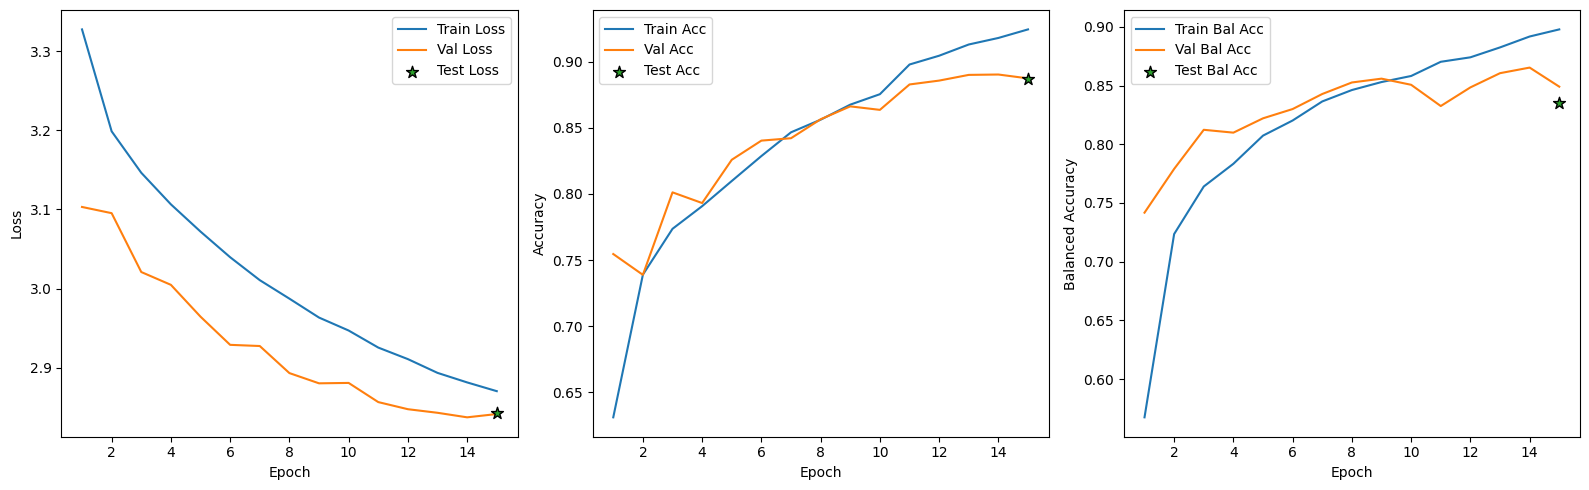


Metrics saved to ./output/build_HHD_model/fold5/metrics.json
Train → Loss: 2.8704, Acc: 0.9243, Balanced Acc: 0.8979
Val → Loss: 2.8415, Acc: 0.8873, Balanced Acc: 0.8491
Test → Loss: 2.8431, Acc: 0.8868, Balanced Acc: 0.8355

--- Cross-Validation Results ---
test_acc: 0.8829 ± 0.0032
test_bal_acc: 0.8333 ± 0.0118
test_loss: 2.8401 ± 0.0028
val_acc: 0.8879 ± 0.0044
val_bal_acc: 0.8494 ± 0.0073


In [148]:
# -- Build a configuration dictionary of the main models
model_configs = {
    "transfer_learn_1": {
    "model_fn": build_HHD_model,
    "lr": 0.0001,
    },  
}

not_training = False

# -- Folds
k_folds = 5

# -- For reproducibility
seed = 42
torch.manual_seed(seed)

# -- Prepare cross-validation
kfold = KFold(n_splits=k_folds, shuffle=True, random_state=seed)

if not_training:
    pass
else:
    # -- 0 Select directory to dump files
    save_dir = "./output"

    # -- 0 Logic begins here
    for name, config in model_configs.items():
        print(f"\nTraining | {name} | {config['model_fn'].__name__}")

        # -- 2 Defines the model
        # print(f"Setting up model: {name}")
        model = config["model_fn"](num_classes=39)

        # -- 3 Save path
        model_name = f"{config['model_fn'].__name__}"
        save_path = os.path.join(save_dir, model_name)
        os.makedirs(save_path, exist_ok=True)

        cv_metrics = []
        for fold, (train_idx, val_idx) in enumerate(kfold.split(train_dataset)):
            print(f"\nFold {fold + 1}")

            # -- 1 Load the Data loaders with these transformations
            train_loader, val_loader, test_loader = build_dataloaders(
                train_idx=train_idx,
                val_idx=val_idx
            )

            # -- 4 Train model. You can go to this function to check what it does...
            metrics = train_transfer_model(
                config=config,
                model_name=model_name,
                train_loader=train_loader,
                val_loader=val_loader,
                test_loader=test_loader,
                epochs=15,
                save_dir=os.path.join(save_path, f"fold{fold+1}"),
                fold=fold + 1 
            )
            
            # Add fold number and store metrics
            metrics["fold"] = fold + 1
            cv_metrics.append({
                "fold": metrics["fold"],
                "test_loss": metrics["test_loss"],
                "test_acc": metrics["test_acc"],
                "test_bal_acc": metrics["test_bal_acc"],
                "val_loss": metrics["val_loss"][-1],            # take last value
                "val_acc": metrics["val_acc"][-1],              # take last value
                "val_bal_acc": metrics["val_bal_acc"][-1],      # take last value
            })


    df = pd.DataFrame(cv_metrics)

    print("\n--- Cross-Validation Results ---")
    for key in ["test_acc", "test_bal_acc", "test_loss", "val_acc", "val_bal_acc"]:
        if key in df.columns:
            mean = df[key].mean()
            std = df[key].std()
            print(f"{key}: {mean:.4f} ± {std:.4f}")
    
    # Save per-fold metrics
    df.to_csv(os.path.join(save_path, "crossval_metrics.csv"), index=False)

## Task 2

In [404]:
# Sampler
class BalancedBatchSampler(BatchSampler):
    """
    Returns batches of size n_classes * n_samples
    """
    def __init__(self, labels, n_classes, n_samples):
        self.labels = labels
        self.labels_set = list(set(self.labels))
        self.label_to_indices = {label: np.where(  np.array(self.labels) == label)[0]
                                 for label in self.labels_set}
        for l in self.labels_set:
            np.random.shuffle(self.label_to_indices[l])
        self.used_label_indices_count = {label: 0 for label in self.labels_set}
        self.count = 0
        self.n_classes = n_classes
        self.n_samples = n_samples
        self.n_dataset = len(self.labels)
        self.batch_size = self.n_samples * self.n_classes

    def __iter__(self):
        self.count = 0
        while self.count + self.batch_size < self.n_dataset:
            classes = np.random.choice(self.labels_set, self.n_classes, replace=False)
            indices = []
            for class_ in classes:
                indices.extend(self.label_to_indices[class_][
                               self.used_label_indices_count[class_]:self.used_label_indices_count[
                                                                         class_] + self.n_samples])
                self.used_label_indices_count[class_] += self.n_samples
                if self.used_label_indices_count[class_] + self.n_samples > len(self.label_to_indices[class_]):
                    np.random.shuffle(self.label_to_indices[class_])
                    self.used_label_indices_count[class_] = 0
            yield indices
            self.count += self.n_classes * self.n_samples

    def __len__(self):
        return self.n_dataset // self.batch_size
    
# Tripplet Loss    
class TripletLoss(nn.Module):
    """
    Triplets loss
    Takes a batch of embeddings and corresponding labels.
    Triplets are generated using triplet_selector object that take embeddings and targets and return indices of
    triplets
    """

    def __init__(self, margin, triplet_selector):
        super(TripletLoss, self).__init__()
        self.margin = margin
        self.triplet_selector = triplet_selector

    def forward(self, embeddings, target):

        triplets = self.triplet_selector.get_triplets(embeddings, target)

        if embeddings.is_cuda:
            triplets = triplets.cuda()

        anchor_idx= triplets[:, 0]  
        positive_idx= triplets[:, 1]  
        negative_idx= triplets[:, 2]

        dist_pos = (embeddings[anchor_idx] - embeddings[positive_idx]).pow(2).sum(1)
        dist_neg = (embeddings[anchor_idx] - embeddings[negative_idx]).pow(2).sum(1)

        losses = F.relu(dist_pos - dist_neg + self.margin)
        return losses.mean()
    
def pdist(vectors):
    distance_matrix = -2 * vectors.mm(torch.t(vectors)) + vectors.pow(2).sum(dim=1).view(1, -1) + vectors.pow(2).sum(
        dim=1).view(-1, 1)
    return distance_matrix

# Semi-hard and hard negatives trippler selector
class Informative_Negative_TripletSelector():
    def __init__(self, margin):
        super(Informative_Negative_TripletSelector, self).__init__()
        self.margin = margin
  
    def get_triplets(self, embeddings, labels):
        if torch.cuda.is_available()==False:
            embeddings = embeddings.cpu()
        distance_matrix = pdist(embeddings)
        distance_matrix = distance_matrix.cpu()

        labels = labels.cpu().data.numpy()
        triplets = []

        for label in set(labels):
            label_mask = (labels == label)
            label_indices = np.where(label_mask)[0]
            if len(label_indices) < 2:
                continue
            negative_indices = np.where(np.logical_not(label_mask))[0]
            anchor_positives = list(combinations(label_indices, 2))  # All anchor-positive pairs
            anchor_positives = np.array(anchor_positives)

            anchor_indices = anchor_positives[:, 0]
            positive_indices = anchor_positives[:, 1]

            # Extract precomputed positive distances:
            dist_pos = distance_matrix[anchor_indices, positive_indices]

            # Extract distances between anchor_indices and negative_indices
            dist_neg = distance_matrix[anchor_indices][:, negative_indices]

            mask = (dist_neg > dist_pos[:, None]) & (dist_neg < (dist_pos + self.margin)[:, None])
            valid_idx = mask.nonzero(as_tuple=False) 

            for i in range(len(anchor_positives)):
                negs_i = valid_idx[valid_idx[:,0]==i][:,1]
                if len(negs_i) > 0:
                    # Semi-hard negatives selection
                    neg_idx = negative_indices[negs_i[torch.randint(len(negs_i), ())]]
                else:
                    # Hard negatives selection
                    neg_idx = negative_indices[dist_neg[i].argmin()]
                
                # Selected tripplets
                triplets.append([anchor_positives[i][0], anchor_positives[i][1], neg_idx])

        return torch.LongTensor(np.array(triplets))

# Main Embedding trainner
class Trainer():
    def __init__(self,
                 model: torch.nn.Module,
                 device: torch.device,
                 criterion: torch.nn.Module,
                 optimizer: torch.optim.Optimizer,
                 training_DataLoader: torch.utils.data.Dataset,
                 validation_DataLoader: torch.utils.data.Dataset ,
                 epochs: int
                 ):
        
        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer
        self.training_DataLoader = training_DataLoader
        self.validation_DataLoader = validation_DataLoader
        self.device = device
        self.epochs = epochs
        self.best_val_loss = float('inf')
        self.scaler = GradScaler()

        self.train_loss_history = []
        self.val_loss_history = []
        self.recall_history = []

    def run_trainer(self):
        for epoch in tqdm(range(self.epochs)):
            self.model.train()  # train mode

            train_losses=[]
            for batch in self.training_DataLoader:

                x,y=batch
                input, target = x.to(self.device), y.to(self.device)  # send to device (GPU or CPU)
                self.optimizer.zero_grad()  # zerograd the parameters
                
                with autocast():  # Mixed precision starts here
                    out = self.model(input, return_embeddings=True)
                    loss = self.criterion(out, target)

                self.optimizer.zero_grad()
                self.scaler.scale(loss).backward()
                self.scaler.step(self.optimizer)
                self.scaler.update()
                
                loss_value = loss.item()
                train_losses.append(loss_value)
                 
                # Optional: clear batch variables to free memory
                del input, target, out, loss
                torch.cuda.empty_cache()


            self.model.eval()  # evaluation mode
            valid_losses = []  # accumulate the losses here

            all_embeddings = []
            all_labels = []
            with torch.no_grad():
                for batch in self.validation_DataLoader:

                    x,y=batch
                    input, target = x.to(self.device), y.to(self.device)  # send to device (GPU or CPU)
                
                    out = self.model(input, return_embeddings=True)   # one forward pass
                    loss = self.criterion(out, target) # calculate loss
                    
                    loss_value = loss.item()
                    valid_losses.append(loss_value)

                    all_embeddings.append(out)
                    all_labels.append(target)

                    del input, target, out, loss_value
                    torch.cuda.empty_cache()

                embeddings = torch.cat(all_embeddings)
                labels = torch.cat(all_labels)

                recall = compute_recall_at_k(embeddings, labels, k=5)
                print(f"Recall@5: {recall:.4f}")
                # plot_embeddings_live(embeddings, labels, epoch=epoch, recall=recall, method='tsne')

                # print the results
                print(
                    f'EPOCH: {epoch+1:0>{len(str(self.epochs))}}/{self.epochs}',
                    end=' '
                )
                print(f'LOSS: {np.mean(train_losses):.4f}',end=' ')
                print(f'VAL-LOSS: {np.mean(valid_losses):.4f}',end='\n')

                # 🔄 FREE MEMORY AFTER EPOCH
                torch.cuda.empty_cache()
                torch.cuda.ipc_collect()
        
            self.train_loss_history.append(np.mean(train_losses))
            self.val_loss_history.append(np.mean(valid_losses))
            self.recall_history.append(recall)
            plot_recall_loss_live(self.train_loss_history,self.val_loss_history,self.recall_history)

        torch.save(self.model.state_dict(), "last_model.pt")
        print("📦 Saved final model as last_model.pt")


def plot_embeddings_live(embeddings, labels, epoch, recall=None, method='pca', max_points=1000):
    """Plots 2D embedding projections (PCA or t-SNE)."""
    embeddings = embeddings.detach().cpu().numpy()
    labels = labels.detach().cpu().numpy()

    if len(embeddings) > max_points:
        idx = np.random.choice(len(embeddings), max_points, replace=False)
        embeddings = embeddings[idx]
        labels = labels[idx]

    if method == 'tsne':
        reducer = TSNE(n_components=2, init='random', perplexity=30)
    elif method == 'pca':
        reducer = PCA(n_components=2)
    else:
        raise ValueError("method must be 'pca' or 'tsne'")

    reduced = reducer.fit_transform(embeddings)
    clear_output(wait=True) 
    plt.figure(figsize=(6, 6))
    scatter = plt.scatter(reduced[:, 0], reduced[:, 1], c=labels, cmap='tab10', s=10, alpha=0.8)
    plt.suptitle(f"Epoch {epoch} - {method.upper()} Embedding\nRecall@5 = {recall:.4f}", fontsize=12)
    plt.colorbar(scatter, ticks=np.unique(labels))
    plt.tight_layout()
    # plt.savefig(f"embedding_epoch{epoch:03d}.png", dpi=150)
    plt.show()


def plot_recall_loss_live(train_loss_hist,val_loss_hist,recall_hist):
    clear_output(wait=True)
    plt.figure(figsize=(12, 5))
    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(train_loss_hist, label="Train Loss")
    plt.plot(val_loss_hist, label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Loss over Epochs")
    plt.legend()

    # Recall@1 plot
    plt.subplot(1, 2, 2)
    plt.plot(recall_hist, label="Recall@5")
    plt.xlabel("Epoch")
    plt.ylabel("Recall@5")
    plt.title("Recall@5 over Epochs")
    plt.legend()
    plt.tight_layout()
    plt.show()


def compute_recall_at_k(embeddings, labels, k=1):
    # Normalize embeddings
    embeddings = torch.nn.functional.normalize(embeddings, p=2, dim=1)

    # Compute cosine similarity
    sim_matrix = embeddings @ embeddings.T

    # Set diagonal to -inf to avoid matching with self
    sim_matrix.fill_diagonal_(-float('inf'))

    # Get top-K nearest neighbor indices
    topk_indices = torch.topk(sim_matrix, k=k, dim=1).indices  # shape (N, K)

    # Compare predicted neighbor labels with true label
    topk_labels = labels[topk_indices]  # shape (N, K)
    correct = (topk_labels == labels.unsqueeze(1)).any(dim=1)

    recall_at_k = correct.float().mean().item()
    return recall_at_k


colors = cm.get_cmap('tab20', 40)  # 40 distinguishable colors
markers = ['o', 's', '^', 'v', '*', 'X', 'D', 'P', 'H', '<', '>']

def extract_embeddings(dataloader, model, embedding_dim=8192, device='cuda'):
    model.eval()
    embeddings = np.zeros((len(dataloader.dataset), embedding_dim))
    labels = np.zeros(len(dataloader.dataset))
    k = 0

    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            emb = model.get_embedding(images).cpu().numpy()
            embeddings[k:k+len(images)] = emb
            labels[k:k+len(images)] = targets.numpy()
            k += len(images)

    return embeddings, labels


def plot_tsne_embeddings(embeddings, labels, label_map, name=None, num_class_show=0):
    """
    embeddings: np.array of shape (N, D)
    labels: array-like of shape (N,)
    label_map: dict[int -> str] for class names
    num_class_show: if > 0, only plot samples from the first `num_class_show` class indices (sorted)
    """

    # Convert to numpy
    embeddings = np.array(embeddings)
    labels = np.array(labels)

    # Optional: filter to first N class indices
    if num_class_show > 0:
        selected_classes = sorted(np.unique(labels))[:num_class_show]
        mask = np.isin(labels, selected_classes)
        embeddings = embeddings[mask]
        labels = labels[mask]

    tsne = TSNE(n_components=2, init='random', random_state=42)
    reduced = tsne.fit_transform(embeddings)

    unique_labels = np.unique(labels)
    n_classes = len(unique_labels)
    
    # Use a high-contrast colormap
    cmap = plt.get_cmap('tab20')  # or try 'tab20b', 'Set3', 'hsv'
    colors = [cmap(i % 20) for i in range(n_classes)]

    plt.figure(figsize=(6, 6))
    
    for idx, label in enumerate(unique_labels):
        inds = np.where(labels == label)[0]
        plt.scatter(reduced[inds, 0], reduced[inds, 1],
                    color=colors[idx],
                    alpha=0.6,
                    label=label_map.get(label, f"Class {label}"),
                    s=12)
        
        # ✅ 2. Add text annotation at the cluster centroid
        centroid = reduced[inds].mean(axis=0)
        class_name = label_map.get(label, f"Class {label}")
        plt.text(centroid[0], centroid[1], class_name,
                 fontsize=6, ha='center', va='center', weight='bold')

    title = f't-SNE - {name}' if num_class_show == 0 else f't-SNE (Top {num_class_show} classes {name})'
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_79045/445403210.py:302: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab20', 40)  # 40 distinguishable colors


In [388]:
train_batch_sampler = BalancedBatchSampler(train_dataset.targets, n_classes=10, n_samples=25)
test_batch_sampler = BalancedBatchSampler(main_test_dataset.targets, n_classes=10, n_samples=25)

triplets_train_loader = torch.utils.data.DataLoader(train_dataset, batch_sampler=train_batch_sampler)
triplets_test_loader = torch.utils.data.DataLoader(main_test_dataset, batch_sampler=test_batch_sampler)

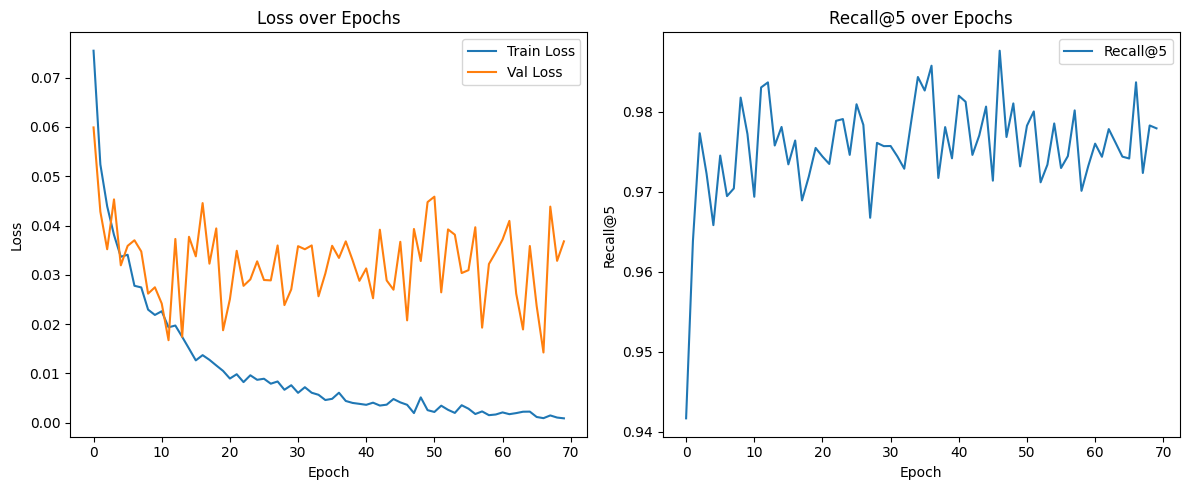

100%|██████████| 70/70 [1:12:39<00:00, 62.27s/it]


📦 Saved final model as last_model.pt


In [389]:
# device
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device=torch.device('cpu')
    
# model
embedding_net = CNET_HHD0_V44(num_classes=39, input_shape=(3, 60, 80))
# embedding_net.load_state_dict(torch.load("last_model_SGD_60epochs.pt"))
mined_model = embedding_net.to(device)

# margin value
margin=0.2

# criterion
criterion = TripletLoss(margin,  Informative_Negative_TripletSelector(margin))

# optimizer
optimizer = torch.optim.SGD(mined_model.parameters(), lr=0.1, momentum=0.8)

# trainer
trainer = Trainer(model=mined_model,
                  device=device,
                  criterion=criterion,
                  optimizer=optimizer,
                  training_DataLoader=triplets_train_loader,
                  validation_DataLoader=triplets_test_loader,
                  epochs=70)

# start training
not_training = False

if not_training:
    pass
else:
    trainer.run_trainer()

In [ ]:
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# mined_model_2 = CNET_HHD0_V44(num_classes=39, input_shape=(3, 60, 80))  # use same args as training
# mined_model_2.load_state_dict(torch.load("last_model_SGD_60epochs.pt"))
# mined_model_2 = mined_model_2.to(device)  # e.g., cpu or cuda

In [390]:
# Generate loaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32)
main_test_loader = torch.utils.data.DataLoader(main_test_dataset, batch_size=32)
new_test_loader = torch.utils.data.DataLoader(new_test_dataset, batch_size=32)
main_support_loader = torch.utils.data.DataLoader(main_support_dataset, batch_size=32)
new_support_loader = torch.utils.data.DataLoader(new_support_dataset, batch_size=32)
merged_test_loader = torch.utils.data.DataLoader(merged_test_dataset, batch_size=32)
merged_support_loader = torch.utils.data.DataLoader(merged_support_dataset, batch_size=32)

# datasets with categories
main_test_cat_loader = torch.utils.data.DataLoader(main_test_dataset_cat, batch_size=32, shuffle=False, num_workers=2)
main_support_cat_loader = torch.utils.data.DataLoader(main_support_dataset_cat, batch_size=32, shuffle=False, num_workers=2)

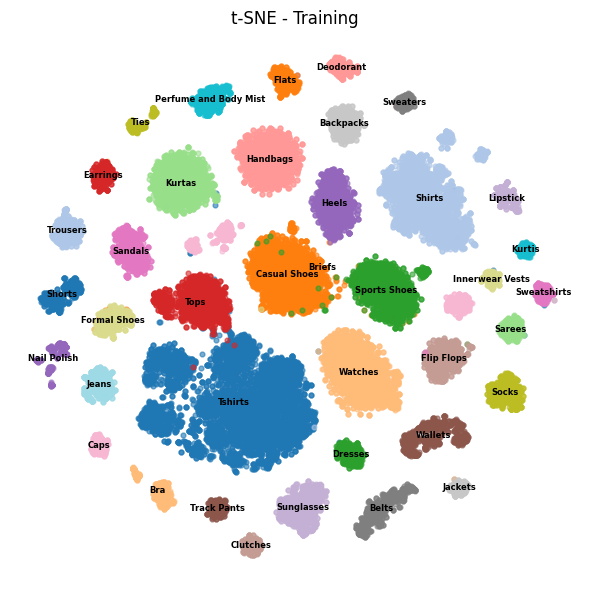

In [391]:
m_train_embeddings, m_train_labels = extract_embeddings(train_loader, mined_model, embedding_dim=8192)
plot_tsne_embeddings(m_train_embeddings, m_train_labels, label_map, name="Training")

In [397]:
from torchvision.transforms.functional import to_pil_image

def evaluate_knn(support_loader, test_loader, model, k=5, device='cuda',name=None):
    # Step 1: Extract embeddings
    support_embeddings, support_labels = extract_embeddings(support_loader, model, device=device)
    test_embeddings, test_labels = extract_embeddings(test_loader, model, device=device)

    # Step 2: Normalize
    support_embeddings = F.normalize(torch.tensor(support_embeddings), dim=1)
    test_embeddings = F.normalize(torch.tensor(test_embeddings), dim=1)

    # Step 3: Similarity & kNN
    sim_matrix = torch.matmul(test_embeddings, support_embeddings.T)
    topk_indices = torch.topk(sim_matrix, k=k, dim=1).indices
    topk_labels = support_labels[topk_indices]
    predicted_labels, _ = mode(topk_labels, axis=1)
    predicted_labels = predicted_labels.squeeze()

    return test_labels, predicted_labels


### 2.2 Assess the performance of your classification method in the 4 different scenarios.

In [398]:
# Evaluate performance of 4 difference scenarions
test_labels_1, predicted_labels_1 = evaluate_knn(train_loader, main_test_loader, mined_model, k=3, device='cuda', name="Scenario 1")
test_labels_2, predicted_labels_2 = evaluate_knn(main_support_loader, main_test_loader, mined_model, k=3, device='cuda', name="Scenario 2")
test_labels_3, predicted_labels_3 = evaluate_knn(new_support_loader, new_test_loader, mined_model, k=3, device='cuda', name="Scenario 3")
test_labels_4, predicted_labels_4 = evaluate_knn(merged_support_loader, merged_test_loader, mined_model, k=3, device='cuda', name="Scenario 4")

# Construct a DataFrame
results = pd.DataFrame({
    "Scenario": ["1", "2", "3", "4"],
    "Description": [
        "Main train    → Main test",
        "Main support  → Main test",
        "New support   → New test",
        "Main+New support → Main+New test"
    ],
    "Accuracy": [
        accuracy_score(test_labels_1, predicted_labels_1),
        accuracy_score(test_labels_2, predicted_labels_2),
        accuracy_score(test_labels_3, predicted_labels_3),
        accuracy_score(test_labels_4, predicted_labels_4)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(test_labels_1, predicted_labels_1),
        balanced_accuracy_score(test_labels_2, predicted_labels_2),
        balanced_accuracy_score(test_labels_3, predicted_labels_3),
        balanced_accuracy_score(test_labels_4, predicted_labels_4)
    ]
})

# Round for readability
results["Accuracy"] = results["Accuracy"].round(3)
results["Balanced Accuracy"] = results["Balanced Accuracy"].round(3)

# Display the table
print(results)

  Scenario                       Description  Accuracy  Balanced Accuracy
0        1         Main train    → Main test     0.911              0.867
1        2         Main support  → Main test     0.895              0.858
2        3          New support   → New test     0.798              0.780
3        4  Main+New support → Main+New test     0.779              0.745


# Task 3

In [399]:
# Denormalization helper
def denormalize(tensor, mean, std):
    mean = torch.tensor(mean).view(-1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1)
    return tensor * std + mean

def plot_class_examples(dataset, label_map=None, n_classes=10, seed=42):
    """
    Plot one image per class (up to n_classes) from the given dataset.
    
    Args:
        dataset: PyTorch Dataset object (e.g., FashionDataset).
        label_map: Optional dict {label_id: class_name}.
        n_classes: Number of classes to show.
        seed: Random seed for consistent sampling.
    """
    # np.random.seed(seed)
    
    # Find unique class labels
    labels = [dataset[i][1] for i in range(len(dataset))]
    labels = np.array(labels)
    unique_labels = np.unique(labels)
    
    if n_classes < len(unique_labels):
        sampled_labels = np.random.choice(unique_labels, size=n_classes, replace=False)
    else:
        sampled_labels = unique_labels

    # One image per class
    images_by_class = {}
    for idx in range(len(dataset)):
        img, label = dataset[idx]
        # Inside your plot function
        img = denormalize(img.clone(), mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        img = to_pil_image(img)
        if label in sampled_labels and label not in images_by_class:
            images_by_class[label] = img
        if len(images_by_class) == len(sampled_labels):
            break

    # Plot
    plt.figure(figsize=(15, 5))
    for i, (label, img) in enumerate(images_by_class.items()):
        plt.subplot(2, 5, i + 1)
        if isinstance(img, torch.Tensor):
            img = to_pil_image(img)
        plt.imshow(img)
        title = label_map[label] if label_map else f"Class {label}"
        plt.title(title, fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


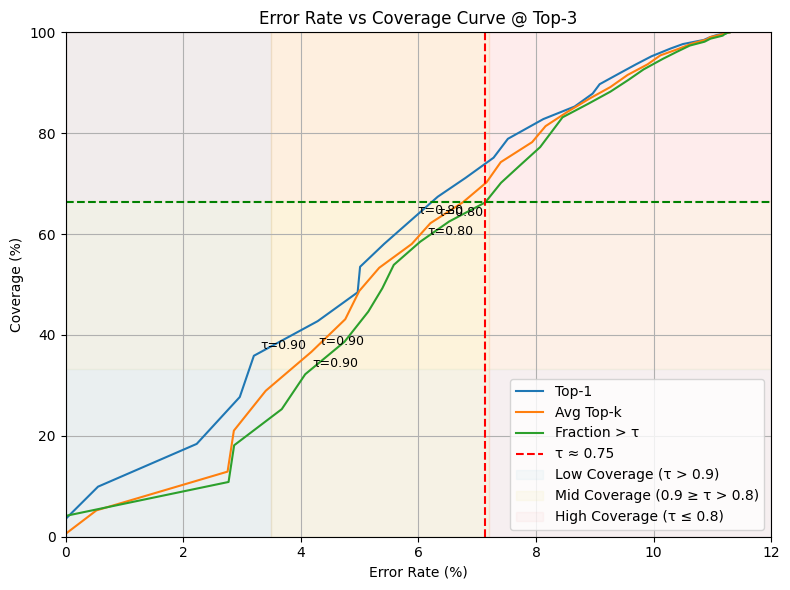

In [428]:
def confidence_fraction_above_threshold(sim_matrix, k=3, sim_threshold=0.75):
    """
    Compute confidence as the fraction of top-k similarities above threshold.
    Returns a confidence score ∈ [0, 1] per sample.
    """
    topk_scores, _ = torch.topk(sim_matrix, k=k, dim=1)
    mask = (topk_scores > sim_threshold).float()
    confidence = mask.sum(dim=1) / k  # fraction above threshold
    return confidence.cpu().numpy()

# def extract_embeddings(dataloader, model, device='cuda'):
#     model.eval()
#     all_embeddings = []
#     all_labels = []
#     with torch.no_grad():
#         for x, y in dataloader:
#             x = x.to(device)
#             emb = model.get_embedding(x)
#             all_embeddings.append(emb.cpu())
#             all_labels.append(y)
#     return torch.cat(all_embeddings).numpy(), torch.cat(all_labels).numpy()

def compute_recall_at_k(sim_matrix, test_labels, support_labels, k=3):
    topk_indices = torch.topk(sim_matrix, k=k, dim=1).indices  # on CUDA
    device = sim_matrix.device  # ensure all tensors align
    support_labels = torch.tensor(support_labels).to(device)
    test_labels = torch.tensor(test_labels).to(device)
    topk_labels = support_labels[topk_indices]  # same device now
    correct = (topk_labels == test_labels.unsqueeze(1)).any(dim=1)
    return correct.cpu().numpy()

def compute_confidence_scores(sim_matrix, mode='top1', k=3):
    topk_scores, _ = torch.topk(sim_matrix, k=k, dim=1)
    if mode == 'top1':
        return topk_scores[:, 0].cpu().numpy()
    elif mode == 'avg_topk':
        return topk_scores.mean(dim=1).cpu().numpy()
    else:
        raise ValueError(f"Unknown confidence mode: {mode}")

def plot_error_vs_coverage(model, test_loader, support_loader, device='cuda', k=3):
    support_embs, support_labels = extract_embeddings(support_loader, model, device=device)
    test_embs, test_labels = extract_embeddings(test_loader, model, device=device)
    support_embs = F.normalize(torch.tensor(support_embs), dim=1).to(device)
    test_embs = F.normalize(torch.tensor(test_embs), dim=1).to(device)
    sim_matrix = torch.matmul(test_embs, support_embs.T)

    correct = compute_recall_at_k(sim_matrix, test_labels, support_labels, k=k)

    strategies = {
        'top1': 'Top-1',
        'avg_topk': 'Avg Top-k',
        'frac_above_τ': 'Fraction > τ ' 
    }

    thresholds = np.linspace(1.0, 0.0, 50)
    plt.figure(figsize=(8, 6))

    for mode, label in strategies.items():

        coverage = []
        error = []

        for tau in thresholds:

            if mode == 'frac_above_τ':
                confidence = confidence_fraction_above_threshold(sim_matrix, k=k, sim_threshold=tau)
            else:
                confidence = compute_confidence_scores(sim_matrix, mode=mode, k=k)        

            mask = confidence >= tau
            if mask.sum() == 0:
                continue
            cov = mask.mean()
            err = 1.0 - correct[mask].mean()
            coverage.append(cov * 100)
            error.append(err * 100)

        plt.plot(error, coverage, label=label)
        # Annotate τ
        for err, cov, tau in zip(error, coverage, thresholds):
            if np.round(tau, 2) in [0.9, 0.8, 0.7]:
                plt.annotate(f"τ={tau:.2f}", (err, cov), textcoords="offset points", xytext=(5, 5), fontsize=9)
    
    highlight_tau = 0.75
    closest_idx = np.argmin(np.abs(np.array(thresholds) - highlight_tau))
    highlight_error = error[closest_idx]
    highlight_coverage = coverage[closest_idx]

    plt.axvline(highlight_error, color='red', linestyle='--', label=f"τ ≈ {highlight_tau:.2f}")
    plt.axhline(highlight_coverage, color='green', linestyle='--')

    # Shade regions
    plt.axvspan(0, 3.5, color='gray', alpha=0.1)
    plt.axvspan(3.5, 7.2, color='orange', alpha=0.1)
    plt.axvspan(7.2, 15, color='red', alpha=0.05)

    plt.axhspan(0, 33.3, color='lightblue', alpha=0.10, label="Low Coverage (τ > 0.9)")
    plt.axhspan(33.3, 66.6, color='khaki', alpha=0.10, label="Mid Coverage (0.9 ≥ τ > 0.8)")
    plt.axhspan(66.6, 100, color='lightcoral', alpha=0.05, label="High Coverage (τ ≤ 0.8)")

    plt.xlabel("Error Rate (%)")
    plt.ylabel("Coverage (%)")
    plt.xlim(0,12)
    plt.ylim(0,100)
    plt.title(f"Error Rate vs Coverage Curve @ Top-{k}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_error_vs_coverage(
    model=mined_model,
    test_loader=merged_test_loader,
    support_loader=merged_support_loader,
    device='cuda',
    k=3  # or 5 if you retrieve 5
)


In [ ]:
def show_top3_recommendations_same_class(model,
                                        test_loader, support_loader, 
                                        test_dataset, support_dataset,
                                        label_map=None,
                                        n_samples=5, device='cuda',
                                        sim_threshold=0.75,
                                        confidence_threshold=33
                                        ):
    """
    Show recommendations only if confidence >= confidence_threshold (%)
    Confidence is estimated as the percentage of top-3 similarities above sim_threshold.
    """    
    # Get Embeddings
    support_embeddings, support_labels = extract_embeddings(support_loader, model, device=device)
    test_embeddings, test_labels = extract_embeddings(test_loader, model, device=device)
    
    support_labels = torch.tensor(support_labels).cpu()
    test_labels = torch.tensor(test_labels)
    
    support_embeddings = F.normalize(torch.tensor(support_embeddings), dim=1).to(device)
    test_embeddings = F.normalize(torch.tensor(test_embeddings), dim=1).to(device)
    
    # Random sample
    num_test = test_embeddings.shape[0]
    indices_ = torch.randperm(num_test)[:n_samples]
    test_embeddings_subset = test_embeddings[indices_]
    test_labels_subset = test_labels[indices_]
    test_samples_subset = [test_dataset[i.item()] for i in indices_]

    # Similarities and Top-k
    similarities = torch.matmul(test_embeddings_subset, support_embeddings.T)
    k = 3
    top_scores, top_indices = torch.topk(similarities, k=k, dim=1)
    top_indices = top_indices.cpu() 
    top_labels = support_labels[top_indices]

    # Compute per-sample confidence
    confidences = []
    for i in range(len(top_scores)):
        count_above = (top_scores[i] > sim_threshold).sum().item()
        confidence = (count_above / k) * 100
        confidences.append(confidence)

    # Plot confident recommendations only
    shown = 0
    plt.figure(figsize=(10, 2.5 * n_samples))

    for i in range(len(test_labels_subset)):
        confidence = confidences[i]
        indices = top_indices[i]
        scores = top_scores[i]
        test_img, _ = test_samples_subset[i]
        test_img = to_pil_image(denormalize(test_img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]))

        # Plot test image
        plt.subplot(n_samples, 4, 4 * shown + 1)
        plt.imshow(test_img)
        class_idx = int(test_labels_subset[i])
        class_name = label_map.get(class_idx, f"Class {class_idx}") if label_map else f"Class {class_idx}"

        if confidence >= confidence_threshold:
            plt.title(f"{class_name}\nConfidence: {confidence:.0f}%")
        else:
            plt.title(f"{class_name}\n⚠ Low Confidence: {confidence:.0f}%")
        plt.axis("off")

        # Show top-3 if confident enough
        if confidence >= confidence_threshold:
            for j in range(3):
                support_img, _ = support_dataset[indices[j].item()]
                support_img = to_pil_image(denormalize(support_img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]))
                plt.subplot(n_samples, 4, 4 * shown + 2 + j)
                plt.imshow(support_img)
                plt.title(f"Top-{j+1}")
                #  (sim={scores[j]:.2f})
                plt.axis("off")

        shown += 1
        if shown >= n_samples:
            break

    plt.tight_layout()
    plt.show()



In [427]:
show_top3_recommendations_same_class(
    model=mined_model,
    test_loader=merged_test_loader,
    support_loader=merged_support_loader,
    test_dataset=merged_test_dataset,
    support_dataset=merged_support_dataset,
    label_map=label_map_2,
    n_samples=60, sim_threshold=0.75,
    confidence_threshold=33
)

# Task 4

#### Step 1
Generate scatter plots of the learned features from the 10 first classes for:

- The main classes train dataset

- The main classes test datasets

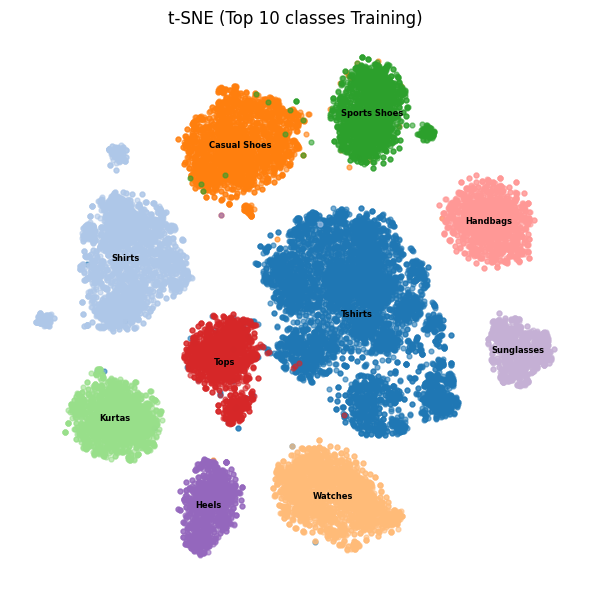

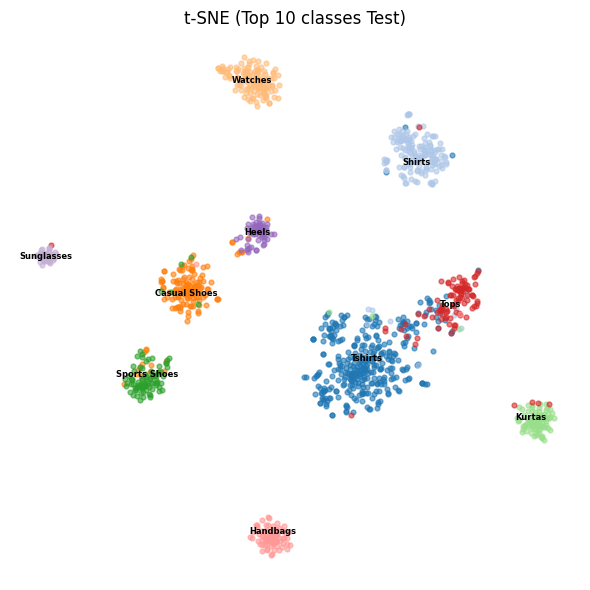

In [407]:
m_train_embeddings, m_train_labels = extract_embeddings(train_loader, mined_model, embedding_dim=8192)
plot_tsne_embeddings(m_train_embeddings, m_train_labels, label_map, name="Training", num_class_show=10)

m_test_embeddings, m_test_labels = extract_embeddings(main_test_loader, mined_model, embedding_dim=8192)
plot_tsne_embeddings(m_test_embeddings, m_test_labels, label_map, name="Test", num_class_show=10)

### Step 2
Confusion matrix:

• Support set: the first 10 classes from the main classes support dataset.

• Test set: the first 10 classes from the main classes test dataset.

In [408]:
def plot_confusion_matrix(test_labels, predicted_labels, map=None, name=None, num_class_show=0):
    # Convert to numpy
    test_labels = np.array(test_labels)
    predicted_labels = np.array(predicted_labels)

    # Determine which classes to show
    if num_class_show > 0:
        selected_classes = sorted(np.unique(test_labels))[:num_class_show]
        mask = np.isin(test_labels, selected_classes)
        test_labels = test_labels[mask]
        predicted_labels = predicted_labels[mask]
    else:
        selected_classes = sorted(np.unique(test_labels))

    # Label names
    target_names = [map[i] if map else f"Class {i}" for i in selected_classes]

    # Classification report with correct label filtering
    report_dict = classification_report(
        test_labels,
        predicted_labels,
        labels=selected_classes,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )

    # Format report into a dataframe (not mandatory for plotting but can be reused)
    df = pd.DataFrame(report_dict).T.iloc[:-3]
    df_sorted = df.sort_values(by="recall", ascending=True).reset_index().rename(columns={"index": "class"})

    # Compute confusion matrix only over selected classes
    cm = confusion_matrix(test_labels, predicted_labels, labels=selected_classes)
    cm_percent = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100
    cm_percent_rounded = np.rint(cm_percent).astype(int)

    # Plot
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(
        cm_percent_rounded,
        xticklabels=target_names,
        yticklabels=target_names,
        cmap='YlGnBu',  
        annot=False,
        fmt='d'
    )

    # Annotate non-zero cells manually
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm_percent_rounded[i, j]
            if val > 0:
                ax.text(j + 0.5, i + 0.5, f"{val}%", ha="center", va="center",
                        color="white" if val > 50 else "black", fontsize=11)

    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix ({name})')
    plt.tight_layout()
    plt.show()


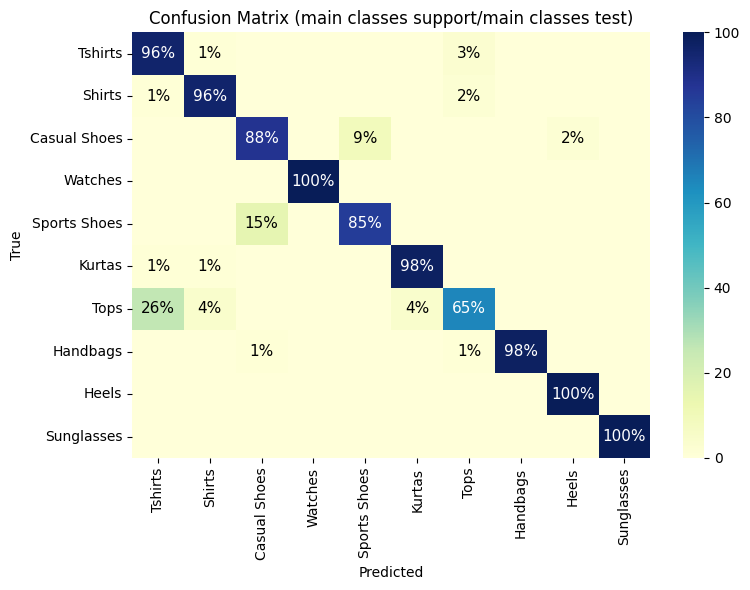

In [409]:
# This confusion matrix is taken from scenario 2 of Task 2
plot_confusion_matrix(test_labels_2, predicted_labels_2, map=label_map, name="main classes support/main classes test", num_class_show=10)

### Step 3
1. Compute the centroids (average feature vectors) for the shirt and T-shirt classes in both train
and test data.
2. For each centroid, display the closest image (in the feature space), representing a “typical”
shirt and T-shirt.
3. By selecting samples close to the line connecting the two centroids, visualize the transition
between shirt and T-shirt in the feature space.

In [410]:
def visualize_shirt_tshirt_transition(support_loader, test_loader, dataset,
                                       shirt_label, tshirt_label, model,
                                       n_steps=7, title="Transition: Shirt ↔ T-shirt"):

    def compute_centroid(embs):
        return embs.mean(axis=0)


    def get_closest_index(embs, target_vec):
        embs_np = embs.cpu().numpy()
        target_np = target_vec.cpu().numpy()
        dists = np.linalg.norm(embs_np - target_np, axis=1)
        return np.argmin(dists)
    

    def make_plots(typical_shirt_idx,typical_tshirt_idx,transition_indices,name=None):
        # Plotting
        plt.figure(figsize=(2 * (n_steps + 2), 3))

        # Left: Typical shirt
        img, _ = dataset[typical_shirt_idx]
        img = to_pil_image(denormalize(img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]))
        plt.subplot(1, n_steps + 2, 1)
        plt.imshow(img)
        plt.title("Typical\nShirt")
        plt.axis("off")

        # Middle: Transition images
        for i, idx in enumerate(transition_indices):
            img, _ = dataset[idx]
            img = to_pil_image(denormalize(img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]))
            plt.subplot(1, n_steps + 2, i + 2)
            plt.imshow(img)
            plt.title(f"α={i / (n_steps - 1):.2f}")
            plt.axis("off")

        # Right: Typical t-shirt
        img, _ = dataset[typical_tshirt_idx]
        img = to_pil_image(denormalize(img, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]))
        plt.subplot(1, n_steps + 2, n_steps + 2)
        plt.imshow(img)
        plt.title("Typical\nT-shirt")
        plt.axis("off")

        plt.suptitle("{} - {}".format(title, name), fontsize=14)
        plt.tight_layout()
        plt.show()


    def filter_and_get_index(embedding, labels,name=None):
        # Filter shirt and t-shirt embeddings
        shirt_inds = np.where(labels == shirt_label)[0]
        tshirt_inds = np.where(labels == tshirt_label)[0]

        shirt_embs = embedding[shirt_inds]
        tshirt_embs = embedding[tshirt_inds]

        # Compute centroids
        shirt_centroid = compute_centroid(shirt_embs)
        tshirt_centroid = compute_centroid(tshirt_embs)

        # Find "typical" shirt and t-shirt
        typical_shirt_idx = shirt_inds[get_closest_index(shirt_embs, shirt_centroid)]
        typical_tshirt_idx = tshirt_inds[get_closest_index(tshirt_embs, tshirt_centroid)]

        # Interpolation in embedding space
        interpolated_points = [
            (1 - alpha) * shirt_centroid + alpha * tshirt_centroid
            for alpha in np.linspace(0, 1, n_steps)
        ]
        embedding = embedding.detach().cpu()
        interpolated_points = [point.detach().cpu() for point in interpolated_points]

        transition_indices = [get_closest_index(embedding, point) for point in interpolated_points]
        
        make_plots(typical_shirt_idx,typical_tshirt_idx,transition_indices,name=name)

    support_embeddings, support_labels = extract_embeddings(support_loader, model, device=device)
    test_embeddings, test_labels = extract_embeddings(test_loader, model, device=device)

    support_labels = torch.tensor(support_labels)
    test_labels = torch.tensor(test_labels)

    support_embeddings = F.normalize(torch.tensor(support_embeddings), dim=1).to(device)
    test_embeddings = F.normalize(torch.tensor(test_embeddings), dim=1).to(device)

    filter_and_get_index(support_embeddings, support_labels, name="Train")
    filter_and_get_index(test_embeddings, test_labels, name="Test")


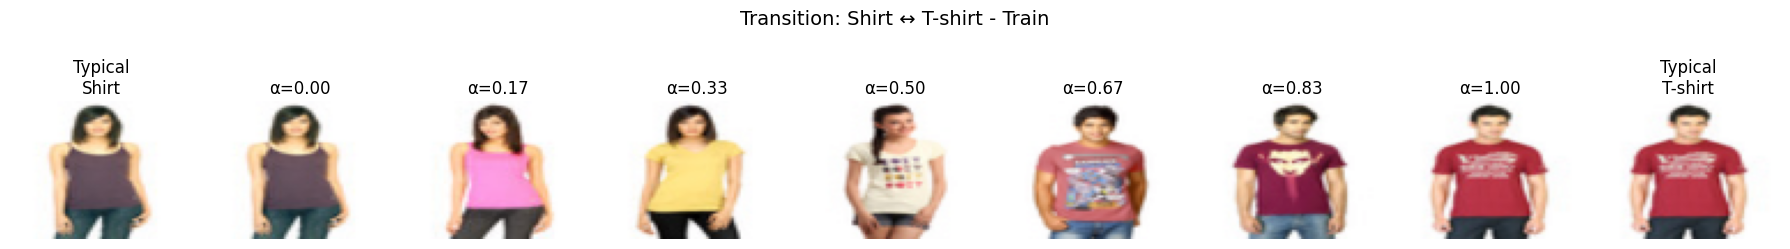

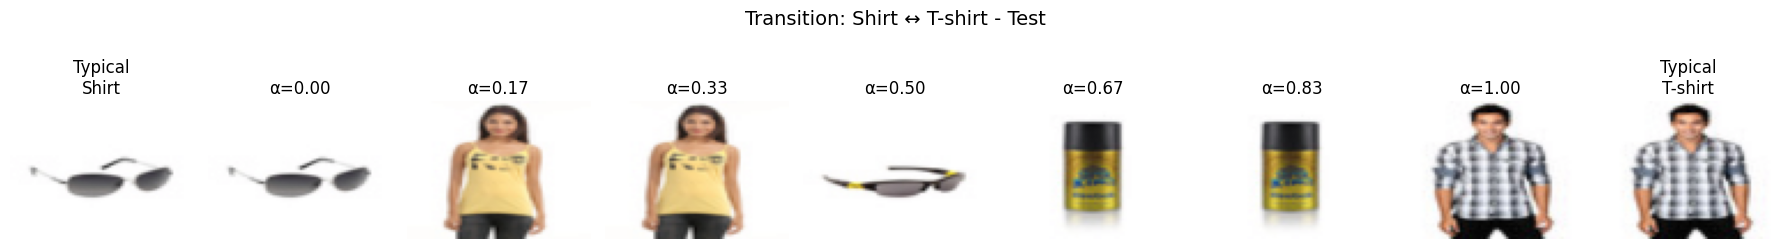

In [411]:
visualize_shirt_tshirt_transition(
    support_loader=train_loader,
    test_loader=main_test_loader,
    dataset=train_dataset,
    shirt_label=6,
    tshirt_label=0,
    n_steps=7,
    model=mined_model
)

### Step 4: Representation of higher level classes

  Scenario                Description  Accuracy  Balanced Accuracy
0        2  Main support  → Main test     0.975              0.959


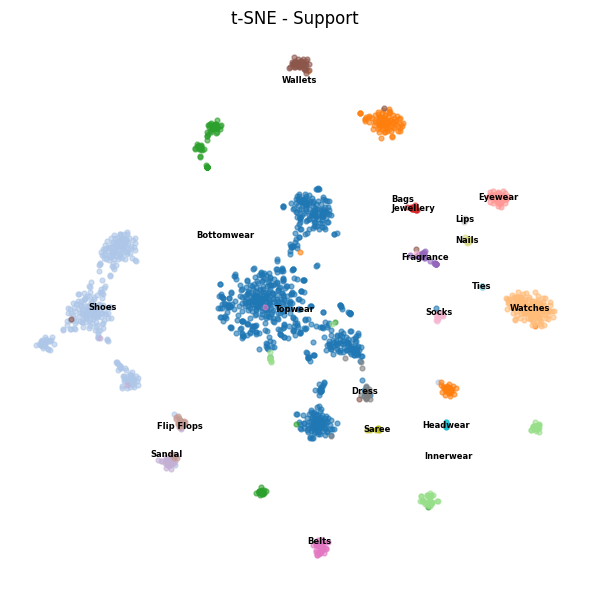

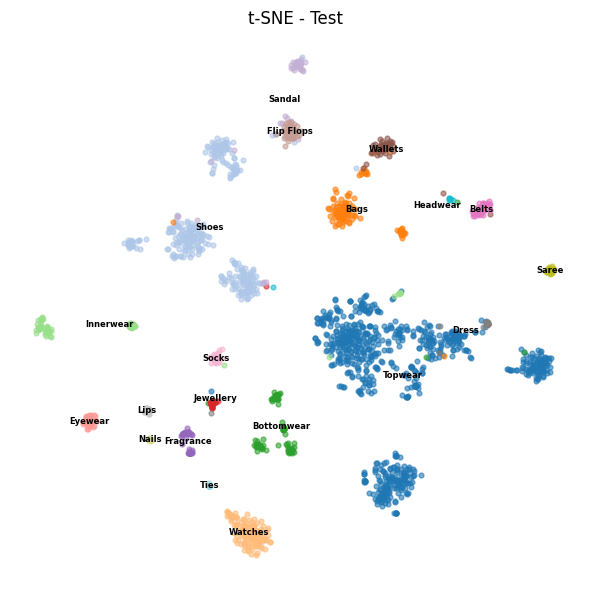

In [413]:
# Evaluate performance of 4 difference scenarions
test_labels_5, predicted_labels_5 = evaluate_knn(main_support_cat_loader, main_test_cat_loader, mined_model, k=3, device='cuda', name="Scenario 1")

# Construct a DataFrame
results = pd.DataFrame({
    "Scenario": ["2"],
    "Description": [
        "Main support  → Main test",
    ],
    "Accuracy": [
        accuracy_score(test_labels_5, predicted_labels_5),
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(test_labels_5, predicted_labels_5),
    ]
})

# Round for readability
results["Accuracy"] = results["Accuracy"].round(3)
results["Balanced Accuracy"] = results["Balanced Accuracy"].round(3)

# Display the table
print(results)

support_embeddings_c, support_labels_c = extract_embeddings(main_support_cat_loader, mined_model, embedding_dim=8192)
plot_tsne_embeddings(support_embeddings_c, support_labels_c, label_map_3, name="Support")

test_embeddings_c, test_labels_c = extract_embeddings(main_test_cat_loader, mined_model, embedding_dim=8192)
plot_tsne_embeddings(test_embeddings_c, test_labels_c, label_map_3, name="Test")